# Phase 4 — Analysis & Insights

Thirteen questions answered against the cleaned dataset (1025 Pokémon, up to
generation IX). Each section shows the metric, a chart and a **Takeaway**;
the consolidated insight list is at the end.

Metrics reused throughout:

* **offense** = `attack + sp_attack`, **bulk** = `hp + defense + sp_defense`,
  **power** = `max(attack, sp_attack)`
* **defensive score** = mean of the 18 incoming `against_*` multipliers
  (lower is better)
* **offense / defense score of a type** = mean multiplier across the full
  18×18 type chart (higher offense is better; lower defense is better)
* **spread** (min-maxing index) = `std(6 stats) / mean(6 stats)` — 0 means a
  perfectly even spread, higher means stats concentrated into a few scores

All logic lives in `scripts/analysis.py`; this notebook presents it.

In [1]:
%matplotlib inline
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")
import analysis as A

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

df = A.add_derived(A.load_clean())
matchups, types = A.load_type_data()
pokemon_abilities, abilities = A.load_ability_data()
print(f"{len(df)} Pokemon, generations {df.generation.min()}-{df.generation.max()}")

1025 Pokemon, generations 1-9


## A. Type matchups

### A1 — Which type is best offensively and defensively?

Offense score = average multiplier that a type deals to all 18 defending
types; defense score = average multiplier it takes from all 18 attacking
types (lower is better).

In [2]:
scores = A.type_scores(matchups, types)
scores[["type", "offense_score", "strong_against", "weak_against", "no_effect",
        "defense_score", "weaknesses", "resistances", "immunities"]]

,type,offense_score,strong_against,weak_against,no_effect,defense_score,weaknesses,resistances,immunities
10,ground,1.166667,5,3,1,1.055556,3,3,1
15,rock,1.138889,4,3,0,1.166667,5,4,0
6,fire,1.111111,4,4,0,1.000000,3,6,0
11,ice,1.111111,4,4,0,1.194444,4,1,0
17,water,1.083333,3,3,0,1.000000,2,4,0
5,fighting,1.083333,5,6,1,1.083333,3,3,0
7,flying,1.083333,3,3,0,1.027778,3,4,1
4,fairy,1.083333,3,3,0,0.972222,2,4,1
16,steel,1.055556,3,4,0,0.833333,3,11,1
1,dark,1.027778,2,3,0,1.055556,3,3,1


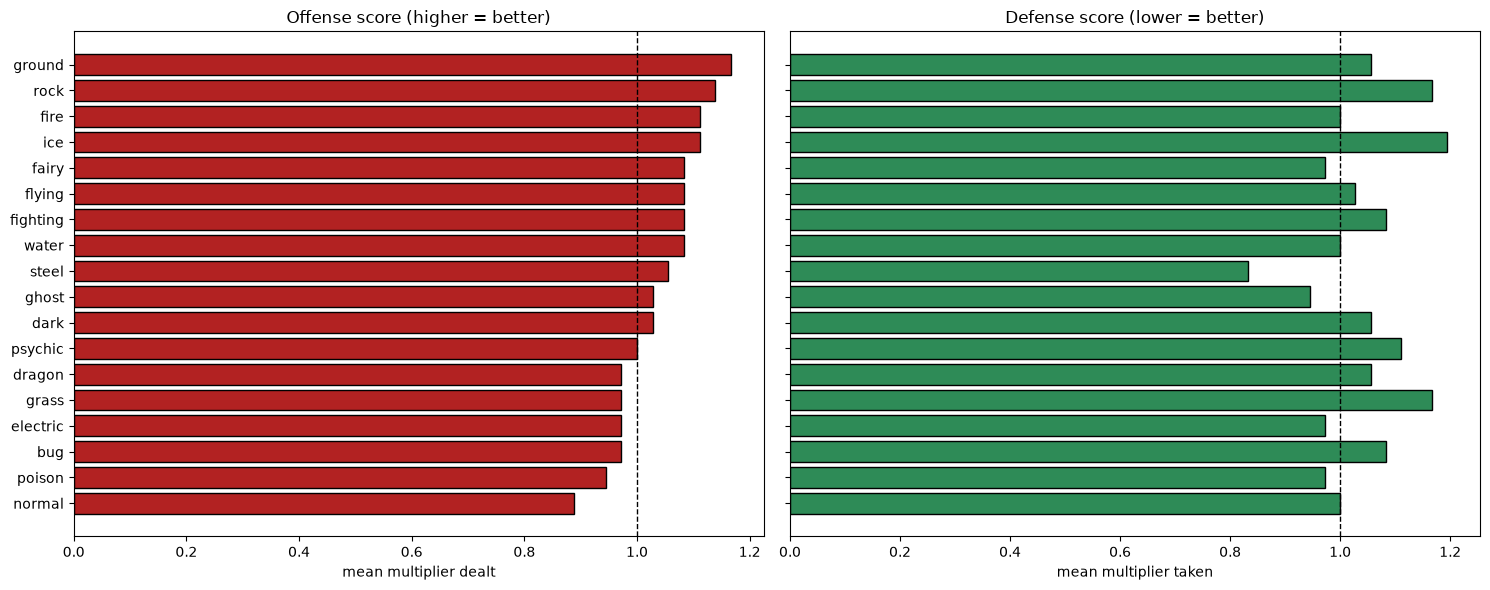

In [3]:
ordered = scores.sort_values("offense_score")
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].barh(ordered.type, ordered.offense_score, color="firebrick", edgecolor="black")
axes[0].axvline(1.0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Offense score (higher = better)")
axes[0].set_xlabel("mean multiplier dealt")

by_def = scores.sort_values("defense_score", ascending=False)
axes[1].barh(by_def.type, by_def.defense_score, color="seagreen", edgecolor="black")
axes[1].axvline(1.0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Defense score (lower = better)")
axes[1].set_xlabel("mean multiplier taken")
plt.tight_layout()

> **Takeaway A1.** **Ground** is the best offensive type (1.167 — 5 types
> weak to it) and **Normal** the worst (0.889 — not strong against anything).
> **Steel** is by far the best defensive type (0.833: 11 resistances + 1
> immunity), while **Ice** is the worst (1.194: 4 weaknesses, only 1
> resistance).

### A2 — Which type *combinations* defend best and worst?

Grouped by `type_pair`, limited to combinations with at least 5 members.

In [4]:
combos = A.combo_scores(df)
best, worst = combos.head(6), combos.tail(6)
print(best.round(3).to_string(index=False))
print()
print(worst.round(3).to_string(index=False))

        type_pair  members  defensive_score  weaknesses  resistances  immunities
            steel       10            0.833         3.0         11.0         1.0
      bug / steel        5            0.875         1.0          9.0         1.0
  steel / psychic        7            0.903         4.0         10.0         1.0
electric / flying        5            0.917         2.0          6.0         1.0
            ghost       16            0.944         2.0          4.0         2.0
         electric       35            0.972         1.0          3.0         0.0

     type_pair  members  defensive_score  weaknesses  resistances  immunities
  bug / flying       13            1.222         5.0          4.0         1.0
grass / flying        6            1.236         5.0          4.0         1.0
  grass / dark        5            1.278         7.0          7.0         1.0
grass / dragon        5            1.292         6.0          4.0         0.0
 rock / ground        6            1.347  

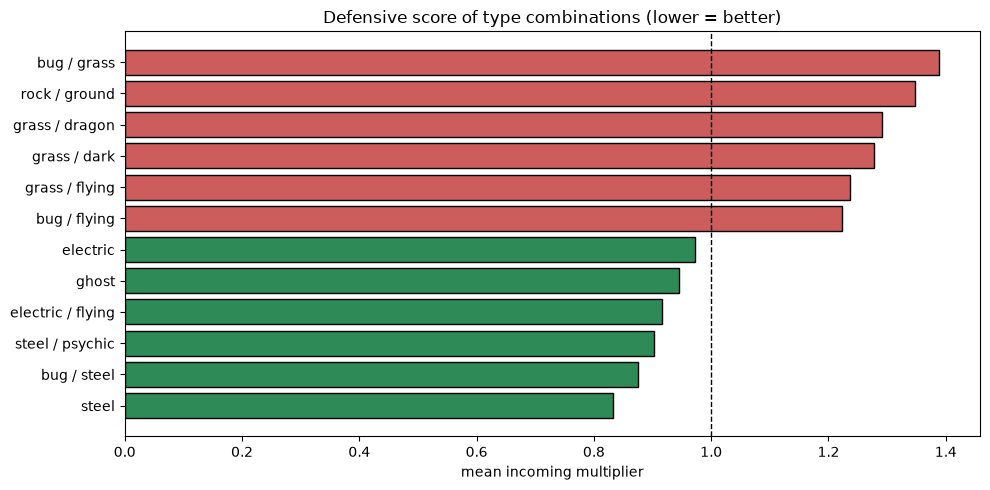

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
show = pd.concat([best.assign(group="best"), worst.assign(group="worst")])
colors = {"best": "seagreen", "worst": "indianred"}
ax.barh(show.type_pair, show.defensive_score,
        color=[colors[g] for g in show.group], edgecolor="black")
ax.axvline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_title("Defensive score of type combinations (lower = better)")
ax.set_xlabel("mean incoming multiplier")
plt.tight_layout()

* **Best:** `steel` (0.833), `bug/steel` (0.875), `steel/psychic` (0.903) —
  stacking Steel's resistances.
* **Worst:** `bug/grass` (1.389), `rock/ground` (1.347), `grass/dragon`
  (1.292) — combinations whose weaknesses *overlap* and leave few resistances.

> **Takeaway A2.** A secondary typing helps only when it adds distinct
> resistances (Steel); when both types share weaknesses (Bug+Grass, Rock+Ground)
> the combination is defensive dead weight.

### A3 — Is dual-typing a net win?

In [6]:
A.dual_tradeoff(df)

,pokemon,mean_base_total,median_base_total,mean_weaknesses,mean_resistances,mean_immunities,mean_defensive_score
typing,,,,,,,
dual,526,451.03,479.5,3.89,5.62,0.90,1.07
single,499,403.08,410.0,2.59,3.38,0.34,1.04


> **Takeaway A3.** Dual types carry **+48 base_total** on average (451 vs
> 403, +12%) but also **1.3 more weaknesses** (3.9 vs 2.6); their defensive
> score is actually slightly *worse* (1.07 vs 1.04). Dual typing buys raw
> power at a small defensive cost, not a free upgrade.

## B. Power over time & stat budgets

### B1 — Power creep across generations?

In [7]:
power_all = A.generation_power(df)
power_non = A.generation_power(df[df.is_legendary == 0])
print("all Pokemon:"); print(power_all)
print("\nnon-legendary:"); print(power_non)

all Pokemon:
            pokemon  mean_base_total  median_base_total
generation                                             
1               151            407.6              405.0
2               100            407.2              415.0
3               135            403.7              410.0
4               107            445.6              480.0
5               156            425.8              445.5
6                72            429.3              450.0
7                88            449.4              480.0
8                96            439.2              481.5
9               120            457.4              488.5

non-legendary:
            pokemon  mean_base_total  median_base_total
generation                                             
1               146            400.9              405.0
2                94            393.8              410.0
3               125            386.7              405.0
4                93            419.8              450.0
5               143

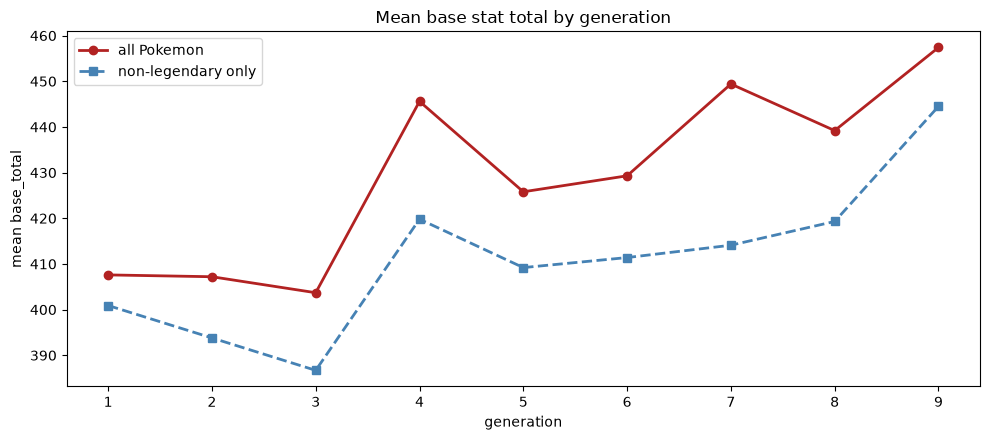

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(power_all.index, power_all.mean_base_total, "o-", label="all Pokemon",
        color="firebrick", linewidth=2)
ax.plot(power_non.index, power_non.mean_base_total, "s--",
        label="non-legendary only", color="steelblue", linewidth=2)
ax.set_title("Mean base stat total by generation")
ax.set_xlabel("generation")
ax.set_ylabel("mean base_total")
ax.set_xticks(range(1, 10))
ax.legend()
plt.tight_layout()

> **Takeaway B1 / B3.** Mean base_total climbs from **408 (gen I) to 457
> (gen IX)** (+12%). The creep is **not** just legendaries: excluding them the
> rise is still **401 → 445** (+11%). Gen III is actually the weakest
> (387 non-legendary) and gen IV the first big jump.

### B2 — Stat budget allocation

Where does the `base_total` budget go? (offense / bulk / speed shares, in %)

In [9]:
alloc = A.budget_allocation(df)
alloc

,offense_share,bulk_share,speed_share
generation,,,
1,34.1,48.7,17.2
2,32.7,52.1,15.2
3,34.6,50.0,15.4
4,34.0,50.2,15.8
5,35.0,49.3,15.6
6,33.6,50.9,15.5
7,35.2,50.0,14.9
8,35.0,49.3,15.7
9,33.9,49.4,16.7


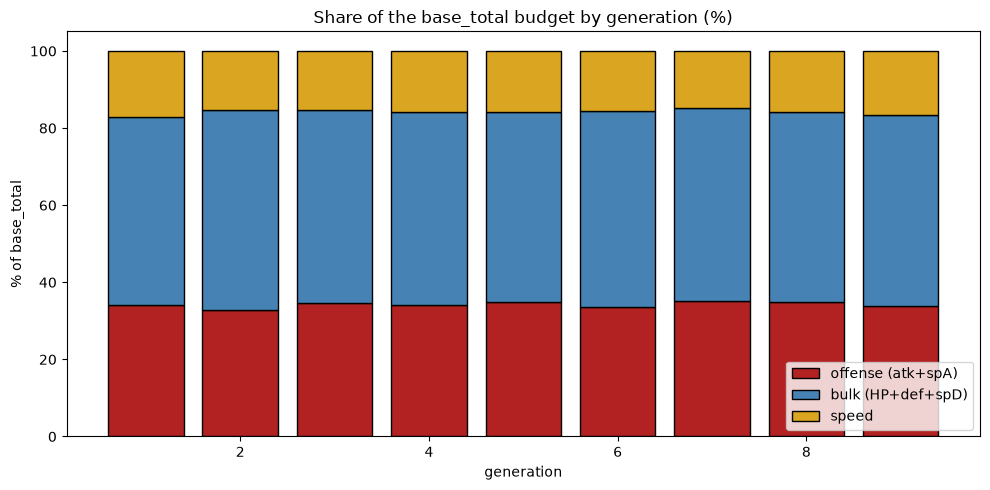

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(alloc.index, alloc.offense_share, label="offense (atk+spA)",
       color="firebrick", edgecolor="black")
ax.bar(alloc.index, alloc.bulk_share, bottom=alloc.offense_share,
       label="bulk (HP+def+spD)", color="steelblue", edgecolor="black")
ax.bar(alloc.index, alloc.speed_share,
       bottom=alloc.offense_share + alloc.bulk_share, label="speed",
       color="goldenrod", edgecolor="black")
ax.set_title("Share of the base_total budget by generation (%)")
ax.set_xlabel("generation")
ax.set_ylabel("% of base_total")
ax.legend(loc="lower right")
plt.tight_layout()

> **Takeaway B2.** The allocation is remarkably **stable**: ~34% offense,
> ~50% bulk, ~16% speed in *every* generation. Later generations get a
> **bigger budget**, not a different-shaped one — speed peaks only slightly
> (17.2% in gen I, 16.7% in gen IX).

### BM — Min-maxing (specialisation)

How concentrated is each Pokémon's stat spread? Higher `spread` = more
min-maxed.

In [11]:
by_gen = A.spread_by(df, "generation").sort_values("generation")
print(by_gen.to_string(index=False))
print()
print(A.spread_legendary(df).to_string())

 generation  pokemon  mean_spread
          1      151        0.287
          2      100        0.287
          3      135        0.286
          4      107        0.269
          5      156        0.261
          6       72        0.243
          7       88        0.285
          8       96        0.265
          9      120        0.263

               pokemon  mean_spread  mean_base_total
non-legendary      924        0.278          409.897
legendary          101        0.225          590.436


most min-maxed types:
     type_pair  pokemon  mean_spread
         rock       17        0.449
rock / ground        6        0.402
        ghost       16        0.362
       ground       17        0.356
 water / rock        5        0.350

most balanced types:
        type_pair  pokemon  mean_spread
           grass       47        0.205
normal / psychic        5        0.202
  grass / flying        6        0.191
          poison       16        0.186
   fire / flying        6        0.172


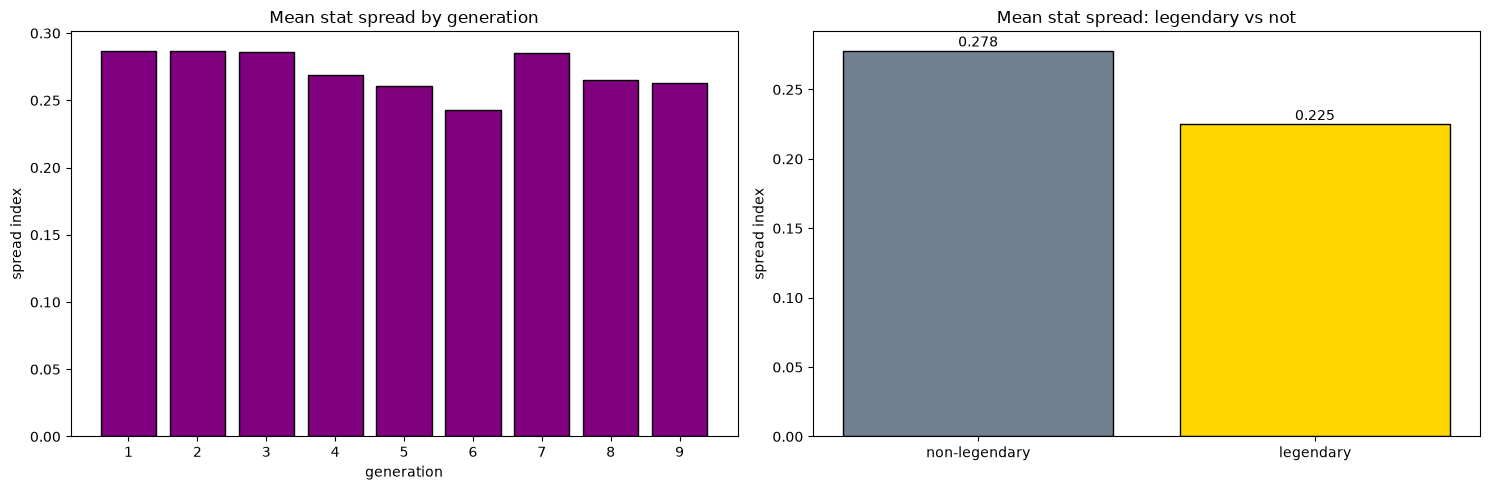

In [12]:
by_type = A.spread_by(df, "type_pair")
by_type = by_type[by_type.pokemon >= 5]
print("most min-maxed types:\n", by_type.head(5).to_string(index=False))
print("\nmost balanced types:\n", by_type.tail(5).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(by_gen.generation, by_gen.mean_spread, color="purple", edgecolor="black")
axes[0].set_title("Mean stat spread by generation")
axes[0].set_xlabel("generation"); axes[0].set_ylabel("spread index")
axes[0].set_xticks(range(1, 10))

leg = A.spread_legendary(df)
axes[1].bar(leg.index, leg.mean_spread, color=["slategray", "gold"], edgecolor="black")
axes[1].set_title("Mean stat spread: legendary vs not")
axes[1].set_ylabel("spread index")
for i, v in enumerate(leg.mean_spread):
    axes[1].text(i, v + 0.003, f"{v:.3f}", ha="center")
plt.tight_layout()

> **Takeaway BM.** Counter-intuitively, **legendaries are *less* min-maxed**
> than average (spread 0.225 vs 0.278) — they're strong across the board rather
> than specialised. Among types, **Rock** is the most min-maxed (0.449: huge
> defense, poor speed/HP) while **Fire/Flying** is the most balanced (0.172).
> The trend across generations is flat-to-slightly-down, so min-maxing did not
> increase over time.

## C. Archetypes

### C1 — Speed vs power: is there a trade-off?

In [13]:
for name, value in A.speed_power(df).items():
    print(f"{name:24s} {value:+.3f}")

corr_speed_power         +0.434
corr_speed_attack        +0.351
corr_speed_sp_attack     +0.423
corr_speed_bulk          +0.169
corr_speed_total         +0.554


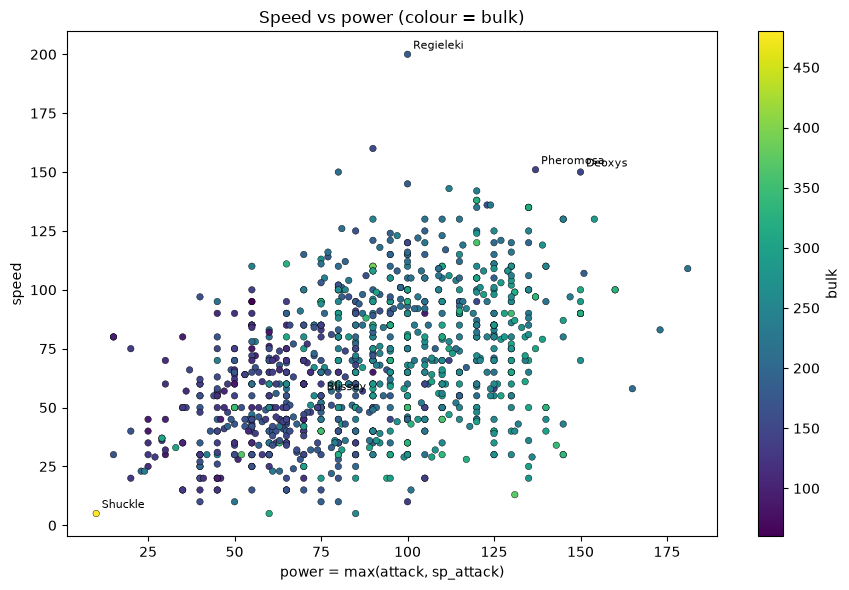

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df.power, df.speed, c=df.bulk, cmap="viridis", s=22,
                edgecolor="black", linewidth=0.3)
ax.set_xlabel("power = max(attack, sp_attack)")
ax.set_ylabel("speed")
ax.set_title("Speed vs power (colour = bulk)")
plt.colorbar(sc, label="bulk")
for name in ["Deoxys", "Pheromosa", "Shuckle", "Blissey", "Regieleki"]:
    row = df[df.name == name]
    if len(row):
        ax.annotate(name, (row.power.iloc[0], row.speed.iloc[0]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.tight_layout()

In [15]:
cannons, tanks = A.archetypes(df)
print("glass cannons (biggest offense-minus-bulk):")
print(cannons.to_string(index=False))
print("\ntanks (biggest bulk-minus-offense):")
print(tanks.to_string(index=False))

glass cannons (biggest offense-minus-bulk):
       name      type_pair  hp  attack  sp_attack  defense  sp_defense  speed  offense  bulk  base_total  gap
     Deoxys        psychic  50     150        150       50          50    150      300   150         600  150
  Pheromosa bug / fighting  71     137        137       37          37    151      274   145         570  129
Blacephalon   fire / ghost  53     127        151       53          79    107      278   185         570   93
   Sharpedo   water / dark  70     120         95       40          40     95      215   150         460   65
   Archeops  rock / flying  75     140        112       65          65    110      252   205         567   47
    Zoroark           dark  60     105        120       60          60    105      225   180         510   45

tanks (biggest bulk-minus-offense):
     name     type_pair  hp  attack  sp_attack  defense  sp_defense  speed  offense  bulk  base_total  gap
  Shuckle    bug / rock  20      10       

> **Takeaway C1.** There is **no speed-vs-power trade-off**: speed
> correlates **positively** with offense (+0.43) and only weakly with bulk
> (+0.17). Faster Pokémon also tend to hit harder, which is why the most
> extreme "glass cannons" (Pheromosa, Deoxys, Blacephalon) pair elite speed
> with elite offense and paper-thin bulk.

## D. Rarity & design

### D1 — Do rarer / slower-growing Pokémon hit harder?

In [16]:
A.rarity_power(df)

,metric,pearson,spearman
0,capture_rate (lower = rarer),-0.730,-0.726
1,base_egg_steps (higher = longer breeding),0.499,0.456
2,experience_growth (higher = slower levelling),0.297,0.333


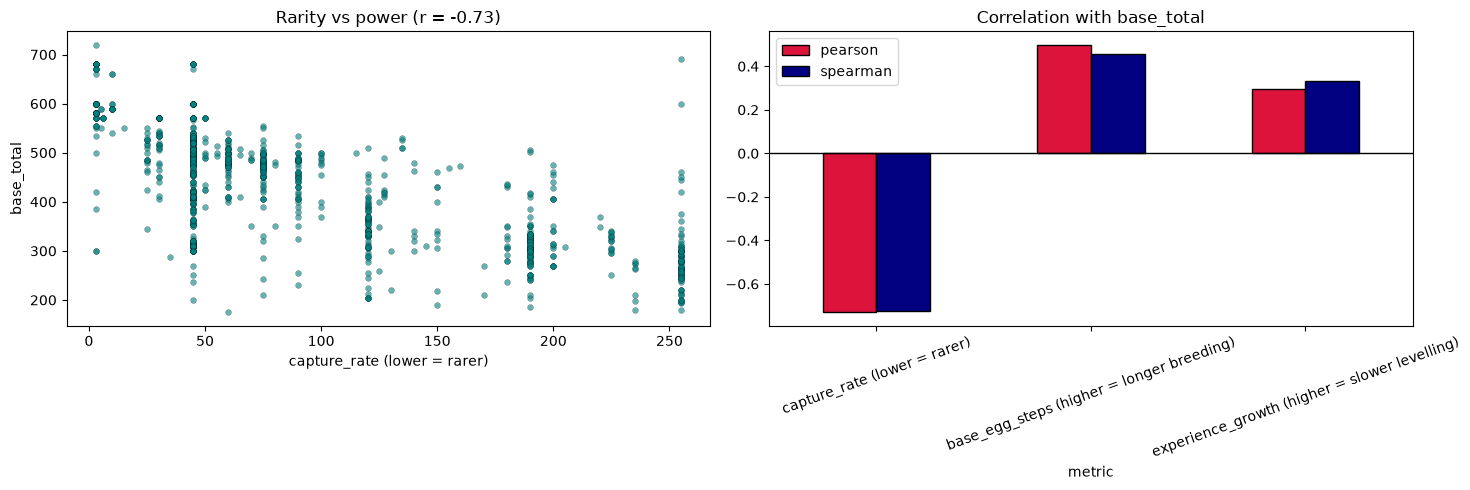

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(df.capture_rate, df.base_total, s=18, alpha=0.6,
                color="teal", edgecolor="black", linewidth=0.2)
axes[0].set_xlabel("capture_rate (lower = rarer)")
axes[0].set_ylabel("base_total")
axes[0].set_title("Rarity vs power (r = -0.73)")

rp = A.rarity_power(df).set_index("metric")
rp[["pearson", "spearman"]].plot(kind="bar", ax=axes[1], color=["crimson", "navy"],
                                 edgecolor="black")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Correlation with base_total")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()

> **Takeaway D1.** Rarity predicts power: `capture_rate` vs `base_total`
> correlates **-0.73** (the rarer the Pokémon, the stronger). Longer breeding
> (`base_egg_steps`, +0.50) and slower growth (`experience_growth`, +0.30) also
> track power, so the "hard to get" Pokémon are systematically the strong ones.

### D2 — How big is the legendary gap?

In [18]:
A.legendary_gap(df)

,non_legendary,legendary,delta,pct
hp,67.5,94.5,26.9,39.9
attack,74.6,103.9,29.3,39.3
defense,69.9,96.7,26.8,38.4
sp_attack,66.4,103.7,37.3,56.1
sp_defense,67.3,97.2,29.9,44.5
speed,64.2,94.5,30.3,47.2
base_total,409.9,590.4,180.5,44.0


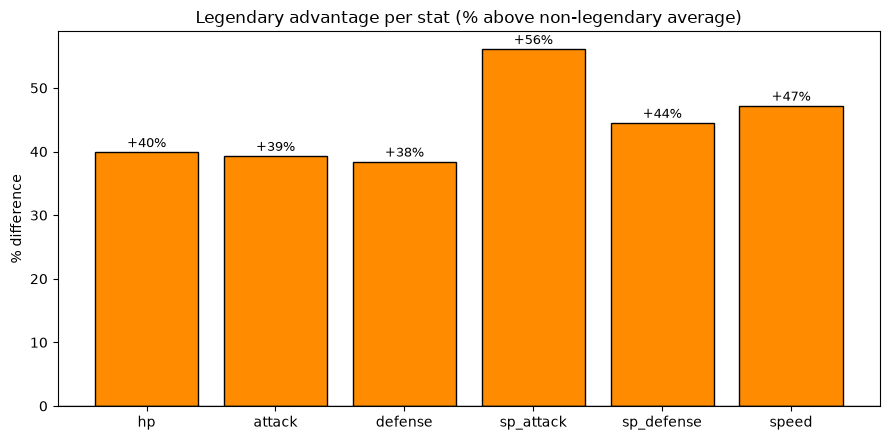

In [19]:
gap = A.legendary_gap(df).drop(index="base_total")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(gap.index, gap.pct, color="darkorange", edgecolor="black")
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Legendary advantage per stat (% above non-legendary average)")
ax.set_ylabel("% difference")
for i, v in enumerate(gap.pct):
    ax.text(i, v + 0.8, f"+{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout()

> **Takeaway D2.** Legendaries average **+180 base_total (+44%)**. The gap is
> biggest in **special attack (+56%)** and **speed (+47%)** and smallest in
> **defense (+38%)** — legendaries are built as fast special attackers, not
> walls.

### D3 — Does size predict power?

height_m vs base_total         0.506
weight_kg vs base_total        0.457
log10(weight) vs base_total    0.599
spearman(weight)               0.648


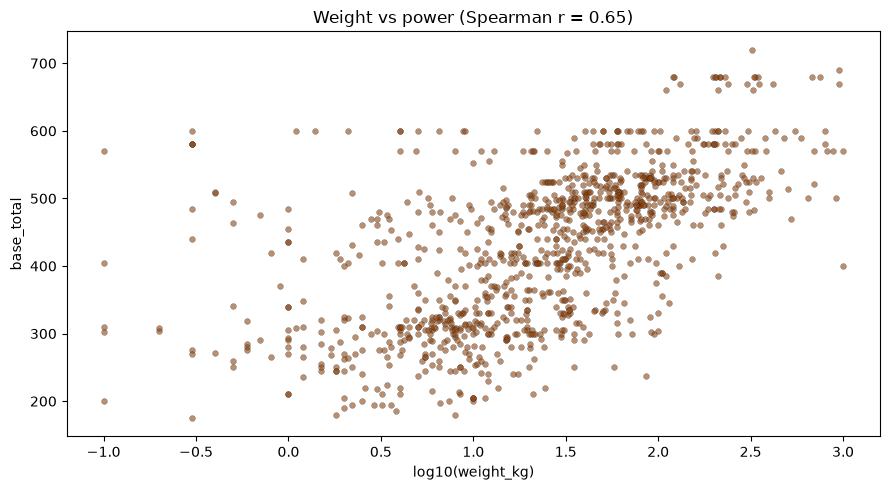

In [20]:
print(A.size_power(df).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(np.log10(df.weight_kg), df.base_total, s=18, alpha=0.6,
           color="saddlebrown", edgecolor="black", linewidth=0.2)
ax.set_xlabel("log10(weight_kg)")
ax.set_ylabel("base_total")
ax.set_title("Weight vs power (Spearman r = 0.65)")
plt.tight_layout()

> **Takeaway D3.** Contrary to the "size tells you nothing" expectation,
> size is a **solid** predictor: weight correlates with base_total at r = 0.46
> (Pearson) and **0.65 (Spearman)** — heavy Pokémon are reliably stronger,
> though there are clear outliers (Wailord is huge but not top-tier).

## E. Abilities

### E2 — Which abilities are shared the most?

In [21]:
freq = A.ability_frequency(pokemon_abilities, abilities)
freq.head(15)

,ability_name,pokemon,as_hidden
0,Swift Swim,44,12
1,Sturdy,42,7
2,Keen Eye,39,5
3,Chlorophyll,37,6
4,Inner Focus,35,11
5,Intimidate,35,7
6,Levitate,32,0
7,Swarm,31,4
8,Run Away,30,8
9,Sheer Force,30,20


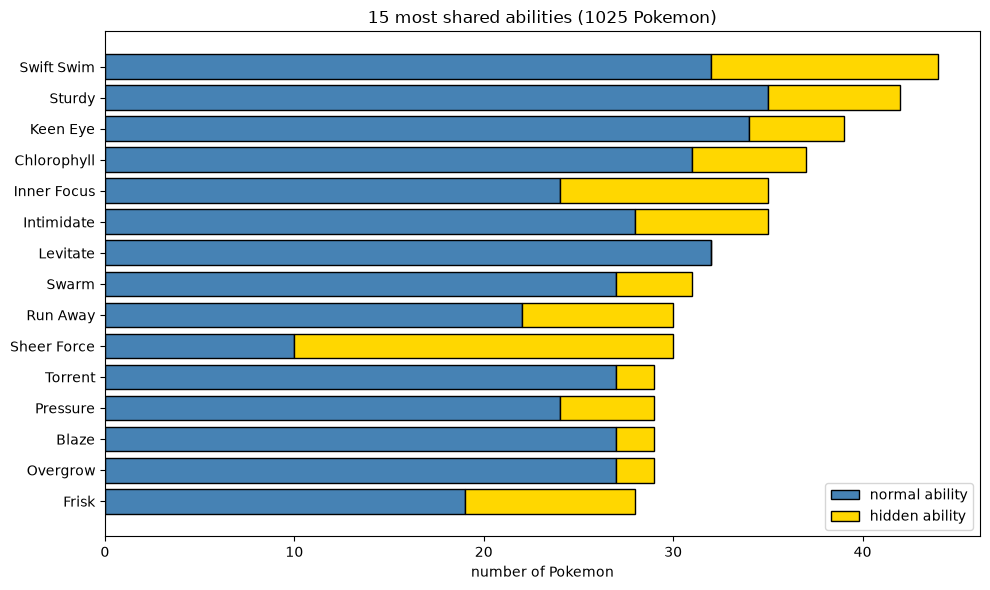

In [22]:
top = freq.head(15).copy()
top["visible"] = top.pokemon - top.as_hidden
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.ability_name, top.visible, color="steelblue", edgecolor="black",
        label="normal ability")
ax.barh(top.ability_name, top.as_hidden, left=top.visible, color="gold",
        edgecolor="black", label="hidden ability")
ax.invert_yaxis()
ax.set_title("15 most shared abilities (1025 Pokemon)")
ax.set_xlabel("number of Pokemon")
ax.legend()
plt.tight_layout()

> **Takeaway E2.** Abilities are heavily recycled: **Swift Swim** appears on
> **44** Pokémon, Sturdy on 42, Keen Eye on 39. The hidden slot is not evenly
> used — **Levitate is never hidden** (0/32) while **Sheer Force is hidden on
> 20 of its 30** carriers. Overall 856 of 2411 ability assignments are hidden.

## Consolidated insights

| # | Insight | Evidence |
|---|---|---|
| 1 | **Steel is the best defensive type, Ice the worst.** | Steel defense score 0.833 (11 resists + 1 immunity); Ice 1.194 (4 weaknesses, 1 resist). |
| 2 | **Best type combos stack Steel; worst pile shared weaknesses.** | `bug/steel` 0.875 vs `bug/grass` 1.389. |
| 3 | **Dual typing trades ~+48 base_total for ~+1.3 weaknesses.** | 451 vs 403 base_total, defensive score 1.07 vs 1.04. |
| 4 | **Power creep is real and not only legendaries.** | Mean base_total 408 (gen I) → 457 (gen IX); non-legendary 401 → 445. |
| 5 | **The stat budget *allocation* never changed.** | ~34% offense / ~50% bulk / ~16% speed in all 9 generations. |
| 6 | **Legendaries are less min-maxed than average.** | Spread 0.225 (legendary) vs 0.278 (non-legendary). |
| 7 | **No speed-vs-power trade-off.** | corr(speed, offense) = +0.43; glass cannons pair top speed *and* top offense. |
| 8 | **Rarity predicts power.** | capture_rate vs base_total r = -0.73; egg-steps +0.50; growth +0.30. |
| 9 | **Legendaries are fast special attackers.** | +180 base_total (+44%), led by sp_attack (+56%) and speed (+47%). |
| 10 | **Size is a genuine (if noisy) power proxy.** | weight vs base_total Spearman r = 0.65. |
| 11 | **Ability slots are heavily reused.** | Swift Swim on 44 Pokémon; 856/2411 assignments are hidden. |

**Next:** Phase 5 — relational schema + ERD, then Phase 6 loading into
PostgreSQL and Phase 7 SQL reports.